s5052032
Chanh Pham
# Deep Learning
# Assigntment 2 Recurrent Neural Networks and NLP

## A. Set up & Data Processing

### Import and Device Control

In [1]:
from datasets import load_dataset    #make sure pip install torch torchtext datasets
import re
from collections import Counter
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import torch.nn as nn
import time

In [61]:
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)

#reproducibility
# torch.manual_seed(42)

Using device: cpu


### Quick data test

In [3]:
dataset = load_dataset("imdb")
train_data = dataset["train"]
test_data  = dataset["test"]

# Quick look
print(train_data[0]["text"][:200])
print("Label:", train_data[0]["label"])

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ev
Label: 0


## B. Tokenisation and Vocabulary

In [4]:
# ── helpers ──────────────────────────────────────────────
def tokenize(text):
    text = text.lower()
    return re.findall(r"\b[a-z']+\b", text)

# Build vocab from training set
VOCAB_SIZE = 20_000
MAX_LEN    = 500
PAD_IDX    = 0
UNK_IDX    = 1

counter = Counter()
for ex in train_data:
    counter.update(tokenize(ex["text"]))

vocab = {"<pad>": PAD_IDX, "<unk>": UNK_IDX}
vocab.update({w: i+2 for i, (w, _) in
              enumerate(counter.most_common(VOCAB_SIZE))})

def encode(text):
    tokens = tokenize(text)[:MAX_LEN]
    return [vocab.get(t, UNK_IDX) for t in tokens]

# ── Dataset class ─────────────────────────────────────────
class IMDbDataset(Dataset):
    def __init__(self, split):
        self.samples = [
            (
                torch.tensor(encode(ex["text"]), dtype=torch.long),
                torch.tensor(ex["label"],        dtype=torch.long)
            )
            for ex in dataset[split]
        ]

    def __len__(self): return len(self.samples)
    def __getitem__(self, i): return self.samples[i]


def collate(batch):
    texts, labels = zip(*batch)
    # Capture true lengths BEFORE padding
    lengths = torch.tensor([len(t) for t in texts], dtype=torch.long)
    texts = pad_sequence(texts, batch_first=True, padding_value=PAD_IDX)
    return texts, torch.stack(labels), lengths  # Return lengths


train_loader = DataLoader(IMDbDataset("train"), batch_size=64,
                          shuffle=True,  collate_fn=collate)
test_loader  = DataLoader(IMDbDataset("test"),  batch_size=64,
                          shuffle=False, collate_fn=collate)

## Task 1.1 VANILLA RNN

In [5]:
class RNNClassifier(nn.Module):
    """ Words to embedding, into RNN model, get the final hidden layer into the output for classification """
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        
        #adding dropout according to the predefined parameters
        self.dropout = nn.Dropout(dropout)
        #fully connected layer
        self.fc = nn.Linear(hidden_dim, n_classes)
        

    def forward(self, x):
        x = self.embedding(x)
        output, hidden = self.rnn(x)
        final_hidden = hidden[-1]
        final_hidden = self.dropout(final_hidden)

        return self.fc(final_hidden)


## Task 2.1 LSTM

In [6]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes,
                 n_layers=2, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        #editted vanilla RNN into LSTM, add dropout keyword parameter because it has multiple layers
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True, dropout=dropout)
        
        #adding dropout according to the predefined parameters
        self.dropout = nn.Dropout(dropout)
        #fully connected layer
        self.fc = nn.Linear(hidden_dim, n_classes)

    # (output, (hidden, cell)) instead of (output, hidden)
    def forward(self, x):
        x = self.embedding(x)
        
        #The one-line change
        output, (hidden, cell) = self.lstm(x)
        
        #keep the rest
        final_hidden = hidden[-1]
        final_hidden = self.dropout(final_hidden)

        return self.fc(final_hidden)
        

## Task 3.1 Bidirectional RNN

In [7]:
class BRNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_classes,
                 n_layers=2, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        # use LSTM as the recurrent layer and make it bidirectional
        self.brnn =nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True, dropout=dropout, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        
        #multiply the input for nn.Linear by 2
        self.fc = nn.Linear(hidden_dim *2, n_classes)

    def forward(self, x):
        x = self.embedding(x)
        
        output, (hidden, cell) = self.brnn(x)
        #final forward hidden state
        forward_hidden = hidden[-2]
        #final backward hidden state
        backward_hidden = hidden[-1]
        #combine the forward and backward hidden layers using torch.cat
        final_hidden = torch.cat((forward_hidden, backward_hidden), dim=1)
        #adding dropout
        final_hidden = self.dropout(final_hidden)

        return self.fc(final_hidden)

## C. Shared Training block

In [8]:
# ── Shared training utilities ─────────────────────────────────
def train_model(model, loader, optimizer, criterion, device):
    """One training epoch. Returns (avg_loss, accuracy)."""

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X, y, lengths in loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        outputs = model(X)

        loss = criterion(outputs, y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == y).sum().item()

        total += y.size(0)

    avg_loss = total_loss / len(loader)

    accuracy = correct / total

    return avg_loss, accuracy


def evaluate_model(model, loader, criterion, device):
    """Evaluation pass (no gradients). Returns (avg_loss, accuracy)."""

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for X, y, lengths in loader:

            X = X.to(device)
            y = y.to(device)

            outputs = model(X)

            loss = criterion(outputs, y)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == y).sum().item()

            total += y.size(0)

    avg_loss = total_loss / len(loader)

    accuracy = correct / total

    return avg_loss, accuracy


def run_training(model, train_loader, test_loader, n_epochs=5, lr=1e-3):
    """Full training run. Returns history dict."""

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
        "epoch_time": []
    }

    for epoch in range(n_epochs):

        start_time = time.time()

        train_loss, train_acc = train_model(
            model,
            train_loader,
            optimizer,
            criterion,
            device
        )

        test_loss, test_acc = evaluate_model(
            model,
            test_loader,
            criterion,
            device
        )

        epoch_time = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {epoch+1}/{n_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )
        
    final_test_acc = history["test_acc"][-1]
    print(f"Final Test Accuracy: {final_test_acc:.4f}")
    
    avg_epoch_time = sum(history["epoch_time"]) / len(history["epoch_time"])
    print(f"Average Epoch Time: {avg_epoch_time:.2f}s")

    return history


## D. Training Loops for RNN, LSTM, and BLSTM

In [13]:
# Initiate
model_rnn = RNNClassifier(
    vocab_size = len(vocab),
    embed_dim  = 128,
    hidden_dim = 256,
    n_classes  = 2
)
print(model_rnn)

#train
history_rnn = run_training(
    model_rnn,
    train_loader,
    test_loader,
    n_epochs=5,
    lr=1e-3)

RNNClassifier(
  (embedding): Embedding(20002, 128)
  (rnn): RNN(128, 256, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)
Epoch 1/5 | Train Loss: 0.7078 | Train Acc: 0.5081 | Test Loss: 0.7001 | Test Acc: 0.4976 | Time: 73.20s
Epoch 2/5 | Train Loss: 0.6968 | Train Acc: 0.5048 | Test Loss: 0.6946 | Test Acc: 0.4958 | Time: 72.47s
Epoch 3/5 | Train Loss: 0.7009 | Train Acc: 0.5104 | Test Loss: 0.7093 | Test Acc: 0.4968 | Time: 68.73s
Epoch 4/5 | Train Loss: 0.7077 | Train Acc: 0.5002 | Test Loss: 0.6975 | Test Acc: 0.5022 | Time: 66.65s
Epoch 5/5 | Train Loss: 0.7062 | Train Acc: 0.4992 | Test Loss: 0.6991 | Test Acc: 0.5018 | Time: 70.33s
Final Test Accuracy: 0.5018
Average Epoch Time: 70.28s


In [12]:
# LSTM
model_lstm = LSTMClassifier(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=256,
    n_classes=2
)
print(model_lstm)

#train
history_lstm = run_training(
    model_lstm,
    train_loader,
    test_loader,
    n_epochs=5,
    lr=1e-3
)

LSTMClassifier(
  (embedding): Embedding(20002, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)
Epoch 1/5 | Train Loss: 0.6946 | Train Acc: 0.4987 | Test Loss: 0.6939 | Test Acc: 0.5034 | Time: 483.16s
Epoch 2/5 | Train Loss: 0.6913 | Train Acc: 0.5094 | Test Loss: 0.6974 | Test Acc: 0.5010 | Time: 387.17s
Epoch 3/5 | Train Loss: 0.6843 | Train Acc: 0.5160 | Test Loss: 0.7022 | Test Acc: 0.5046 | Time: 413.29s
Epoch 4/5 | Train Loss: 0.6678 | Train Acc: 0.5292 | Test Loss: 0.7162 | Test Acc: 0.5052 | Time: 392.45s
Epoch 5/5 | Train Loss: 0.6491 | Train Acc: 0.5397 | Test Loss: 0.7642 | Test Acc: 0.5046 | Time: 557.35s
Final Test Accuracy: 0.5046
Average Epoch Time: 446.68s


In [14]:
#BRNN
model_blstm = BRNNClassifier(
    vocab_size=len(vocab),
    embed_dim=128,
    hidden_dim=256,
    n_classes=2
)
print(model_blstm)

#train
history_blstm = run_training(
    model_blstm,
    train_loader,
    test_loader,
    n_epochs=5,
    lr=1e-3
)

BRNNClassifier(
  (embedding): Embedding(20002, 128)
  (brnn): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=2, bias=True)
)
Epoch 1/5 | Train Loss: 0.6824 | Train Acc: 0.5539 | Test Loss: 0.6562 | Test Acc: 0.6133 | Time: 747.07s
Epoch 2/5 | Train Loss: 0.5366 | Train Acc: 0.7302 | Test Loss: 0.4174 | Test Acc: 0.8133 | Time: 779.21s
Epoch 3/5 | Train Loss: 0.3602 | Train Acc: 0.8488 | Test Loss: 0.3691 | Test Acc: 0.8425 | Time: 792.97s
Epoch 4/5 | Train Loss: 0.2673 | Train Acc: 0.8932 | Test Loss: 0.3078 | Test Acc: 0.8745 | Time: 807.34s
Epoch 5/5 | Train Loss: 0.2116 | Train Acc: 0.9201 | Test Loss: 0.3324 | Test Acc: 0.8584 | Time: 806.22s
Final Test Accuracy: 0.8584
Average Epoch Time: 786.56s


## E. Observations

### Task 1.2

(1). What test accuracy did your vanilla RNN achieve?
- It achieved 50% accuracy after 5 epochs

(2). Plot training loss vs. epoch. Does the model converge? Any sign of overfitting?
- From the loss curve, the model does not converge strongly. There is no sign of overfitting. Instead, the model seems to be underfitting

(3). What is the vanishing gradient problem and why might it affect this model on long reviews? (2–3 sentences, no equations needed.)
- Vanishing gradient occurs when the gradient becomes extremely small due to backpropagation through many time steps. This model, Vanilla RNN, on long reviews take only the final hidden state to used for classification of positive or negative. Vanishing gradient problem makes the final hidden state lose important information in earlier hidden states.

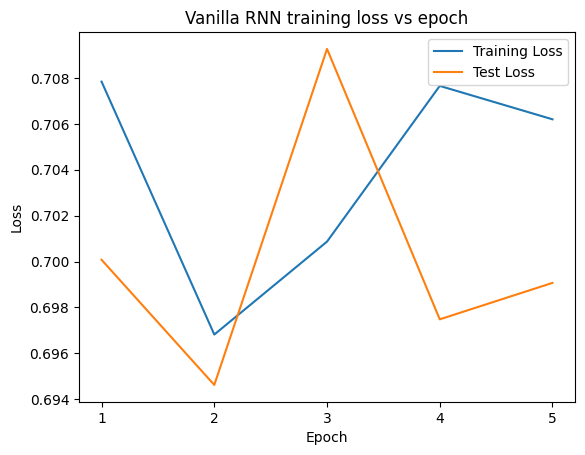

In [23]:
import matplotlib.pyplot as plt

#assign new epoch value with history's epoch index move to the right by 1 to make the graph correct
epochs = range(1, len(history_rnn["train_loss"]) + 1)

plt.plot(epochs, history_rnn["train_loss"], label="Training Loss")
plt.plot(epochs, history_rnn["test_loss"], label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla RNN training loss vs epoch")

plt.xticks(epochs)

plt.legend()

plt.show()


### Task 2.2

(1). Report final test accuracy.
- The final test accuracy is 50%

(2). On the same plot, show training loss curves for both the RNN and the LSTM. Label each line clearly.
- The plot is in the cell below.

(3). Which model trains faster (loss drops quicker)? Why might that be?
- For epoch 1 and 2, the Vanilla RNN model show a steeper loss drop. However, it is not consistent unlike LSTM model, which continues to drop across all epochs. This shows that the LSTM can learn more useful patterns from the training data due to its gate mechanism. LSTM model trains faster, however, it needs more tuning because its test loss increased across epochs, suggesting overfitting.

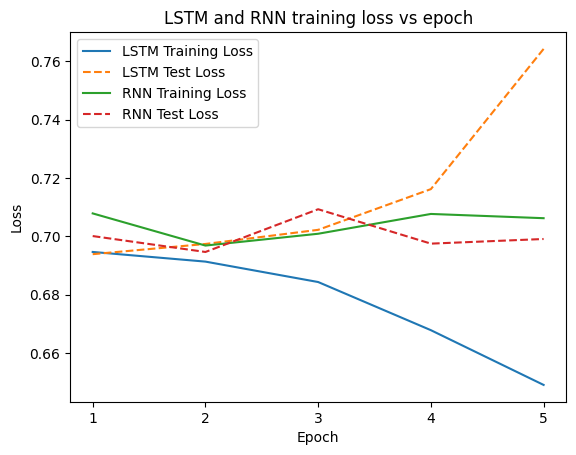

In [28]:
# epochs_lstm = range(1, len(history_lstm["train_loss"]) + 1)  redundant because all trainings have the same epoch. Change this if diff

#LSTM
plt.plot(epochs, history_lstm["train_loss"], label="LSTM Training Loss")
plt.plot(epochs, history_lstm["test_loss"], linestyle="--", label="LSTM Test Loss")

#RNN
plt.plot(epochs, history_rnn["train_loss"], label="RNN Training Loss")
plt.plot(epochs, history_rnn["test_loss"], linestyle="--", label="RNN Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM and RNN training loss vs epoch")

plt.xticks(epochs)


plt.legend()
plt.show()

### Task 3.2
(1). Report final test accuracy.
- The final test accuracy is over 85%.

(2). On the same plot, show training loss curves for the RNN, the LSTM and the BRNN. Label each line clearly.
- The plot is below.

(3). Which model trains faster (loss drops quicker)? Why might that be?
- The BRNN is the best model because it reads the review in both forward and backward directions to use context from both earlier and later words before making the final sentiment prediction.

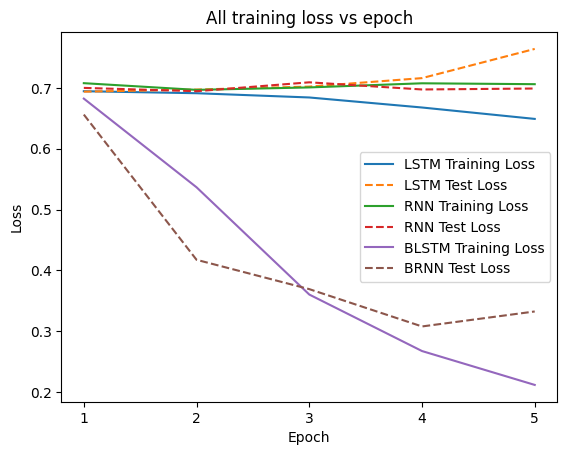

In [31]:
#LSTM
plt.plot(epochs, history_lstm["train_loss"], label="LSTM Training Loss")
plt.plot(epochs, history_lstm["test_loss"], linestyle="--", label="LSTM Test Loss")

#RNN
plt.plot(epochs, history_rnn["train_loss"], label="RNN Training Loss")
plt.plot(epochs, history_rnn["test_loss"], linestyle="--", label="RNN Test Loss")

#BRNN
plt.plot(epochs, history_blstm["train_loss"], label="BLSTM Training Loss")
plt.plot(epochs, history_blstm["test_loss"], linestyle="--", label="BRNN Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("All training loss vs epoch")

plt.xticks(epochs)


plt.legend()
plt.show()

## F. Part 4

In [37]:
import pandas as pd
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def average_epoch_time(history):
    return sum(history["epoch_time"]) / len(history["epoch_time"])


summary_table = pd.DataFrame({
    "Model": ["Vanilla RNN", "LSTM", "BRNN/BLSTM"],
    "Test Accuracy": [
        history_rnn["test_acc"][-1],
        history_lstm["test_acc"][-1],
        history_blstm["test_acc"][-1]
    ],
    "Parameters": [
        count_parameters(model_rnn),
        count_parameters(model_lstm),
        count_parameters(model_blstm)
    ],
    "Avg Epoch Time": [
        average_epoch_time(history_rnn),
        average_epoch_time(history_lstm),
        average_epoch_time(history_blstm)
    ]
})
summary_table

,Model,Test Accuracy,Parameters,Avg Epoch Time
0,Vanilla RNN,0.50180,2659586,70.275202
1,LSTM,0.50464,3482370,446.684962
2,BRNN/BLSTM,0.85840,4928770,786.559461


Write 3–4 sentences interpreting the trade-off between accuracy, model size, and training speed across the three architectures.

- The BRNN has the highest test accuracy, however, it took the longest time to train and have a largest model size comparing to the other 2 models. The Vanilla RNN uses a simple recurrent structure so it needs the least computation power and its training speed is the fastest, in exchange for accuracy. The LSTM model uses gates to control what information to keep or remove, so the model size is higher than the Vanilla RNN and it takes more time to train. The LSTM model also needs careful tuning to achieve higher accuracy, but it's more possible in comparision to Vanilla RNN model.

### Task 4.2 Live Prediction function

In [39]:
def predict_sentiment(text, model, vocab, device):
    model.eval()

    token_ids = encode(text)

    if len(token_ids) == 0:
        token_ids = [UNK_IDX]

    x = torch.tensor(token_ids, dtype=torch.long).unsqueeze(0)
    x = x.to(device)

    with torch.no_grad():
        outputs = model(x)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, prediction = torch.max(probabilities, dim=1)

    label = "Pos" if prediction.item() == 1 else "Neg"

    return label, confidence.item()

In [59]:
# The best model is BRNN/BLSTM
best = model_blstm.to(device)

# 2 positive reviews, 2 ambiguous, 1 negative review
reviews = [ "The actors were very good at portraying the characters, 10 out of 10!", #pos
            
            "I LOVE THE ENDING. I WILL DEFINITELY SEE THIS MOVIE AGAIN WITH MY BEAUTIFUL WIFE", #pos
            
            "Oh man, what to say. The ending is not that great but in general it's not bad." #amb
            
            ,"""I wish I could see more actions. There weren't many action scenes. The male actor couldn't stand 
            up for himself
            unlike what I had thought that he could have done so since the beginning. It's alright though. The female lead's acting was spectacular, 
            I am now her fan and I wish to see her in another movie soon. 
            I believe she would become a rising star and win the grammys this year!. It was a great idea to cast her for this movie.
            In the end thanks to her that the movie was not bad after all! go check it out in theatre""", #amb
            
            "The female lead was such a turn off for me. She made the whole movie look bad." #neg
            ]

#printing results
for review in reviews:
    label, confidence = predict_sentiment(review, best, vocab, device)

    print("Review:", review)
    print("Prediction:", label)
    print("Confidence:", round(confidence, 4))
    print()

Review: The actors were very good at portraying the characters, 10 out of 10!
Prediction: Pos
Confidence: 0.9855

Review: I LOVE THE ENDING. I WILL DEFINITELY SEE THIS MOVIE AGAIN WITH MY BEAUTIFUL WIFE
Prediction: Pos
Confidence: 0.9978

Review: Oh man, what to say. The ending is not that great but in general it's not bad.
Prediction: Neg
Confidence: 0.9723

Review: I wish I could see more actions. There weren't many action scenes. The male actor couldn't stand 
            up for himself
            unlike what I had thought that he could have done so since the beginning. It's alright though. The female lead's acting was spectacular, 
            I am now her fan and I wish to see her in another movie soon. 
            I believe she would become a rising star and win the grammys this year!. It was a great idea to cast her for this movie.
            In the end thanks to her that the movie was not bad after all! go check it out in theatre
Prediction: Neg
Confidence: 0.7926

Review: T

### Task 4.3 Error Analysis

In [47]:
def find_misclassified_examples(model, test_loader, device, max_examples=5):
    model.eval()

    mistakes = []

    with torch.no_grad():

        for X, y, lengths in test_loader:

            X = X.to(device)
            y = y.to(device)

            outputs = model(X)
            predictions = torch.argmax(outputs, dim=1)

            wrong_indices = torch.where(predictions != y)[0]

            for idx in wrong_indices:

                true_length = lengths[idx].item()

                review_tokens = X[idx][:true_length].cpu().tolist()
                review_tokens = review_tokens[:100]

                true_label = "Pos" if y[idx].item() == 1 else "Neg"
                predicted_label = "Pos" if predictions[idx].item() == 1 else "Neg"

                mistakes.append((review_tokens, true_label, predicted_label))

                if len(mistakes) == max_examples:
                    return mistakes

    return mistakes


mistakes = find_misclassified_examples(best, test_loader, device)

# Reverse vocabulary: id -> word
inverse_vocab = {idx: word for word, idx in vocab.items()}

#function to decode token IDs back into words
def decode_tokens(token_ids):
    words = []

    for token in token_ids:
        word = inverse_vocab.get(token, "<unk>")
        words.append(word)

    return " ".join(words)

#print the results
for i, (review_tokens, true_label, predicted_label) in enumerate(mistakes):
    #decode the token IDs into words
    decoded_review = decode_tokens(review_tokens)

    print(f"Example {i+1}")
    print()

    print("Review Text:")
    print(decoded_review)
    print()

    print("True Label:", true_label)
    print("Predicted Label:", predicted_label)
    print("-" * 80)

Example 1

Review Text:
first off let me say if you haven't enjoyed a van damme movie since <unk> you probably will not like this movie most of these movies may not have the best plots or best actors but i enjoy these kinds of movies for what they are this movie is much better than any of the movies the other action guys segal and dolph have thought about putting out the past few years van damme is good in the movie the movie is only worth watching to van damme fans it is not as good as wake of death which i

True Label: Neg
Predicted Label: Pos
--------------------------------------------------------------------------------
Example 2

Review Text:
ben rupert <unk> is a deeply unhappy adolescent the son of his unhappily married parents his father nicholas farrell is a vicar and his mother laura <unk> is well let's just say she's a somewhat hypocritical soldier in jesus army it's only when he takes a summer job as an assistant to a foul mouthed eccentric once famous and now forgotten ac